In [67]:
clean_dataset_drive_url="https://drive.google.com/file/d/1AxchD_W4q0d9lXBOi2gyqunl_TmH3ktm/view?usp=sharing"

In [68]:
import re


def drive_to_direct_url(link: str) -> str:
    """
    Convert Google Drive share link to direct download URL.
    Works for multiple link formats.
    """
    patterns = [
        r'/file/d/([a-zA-Z0-9_-]+)',
        r'id=([a-zA-Z0-9_-]+)',
        r'/open\?id=([a-zA-Z0-9_-]+)'
    ]
    
    file_id = None
    
    for pattern in patterns:
        match = re.search(pattern, link)
        if match:
            file_id = match.group(1)
            break
    
    if not file_id:
        raise ValueError("Invalid Google Drive link")
    
    return f"https://drive.google.com/uc?id={file_id}"

In [69]:

from pathlib import Path

cleaned_dataset_path = Path("diadb-training/cleaned_diabetes.csv")

In [70]:
import pandas as pd

if not cleaned_dataset_path.is_file():
    cleaned_dataset_path = Path("cleaned_diabetes.csv")

df = pd.read_csv(
    cleaned_dataset_path
    if cleaned_dataset_path.is_file()
    else drive_to_direct_url(clean_dataset_drive_url)
)


In [71]:
df.head()

,age,gender,pulse_rate,systolic_bp,diastolic_bp,glucose,bmi,family_diabetes,hypertensive,family_hypertension,cardiovascular_disease,stroke,diabetic
0,42,Female,66,110,73,5.88,25.75,0,0,0,0,0,No
1,35,Female,60,125,68,5.71,19.58,0,0,0,0,0,No
2,62,Female,57,127,74,6.85,20.24,0,0,0,0,0,No
3,73,Male,55,193,112,6.28,21.72,0,0,0,0,0,No
4,68,Female,71,150,81,5.71,17.79,0,0,0,0,0,No


In [72]:
# This baseline needs XGBoost only; imbalance handling is reserved for a later workflow.
%pip install xgboost

In [73]:
X = df.drop(columns=["diabetic"])
y = df["diabetic"]

In [74]:
if y.dtype == "object":
    y = y.map({"No": 0, "Yes": 1})

In [75]:
from sklearn.model_selection import train_test_split

In [76]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

In [77]:
# XGBoost cannot consume text; fit gender encoding on training data to avoid test leakage.
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[("gender", OneHotEncoder(handle_unknown="ignore"), ["gender"])],
    remainder="passthrough",
)
X_train = preprocessor.fit_transform(X_train)
X_test = preprocessor.transform(X_test)

In [78]:
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (4208, 13)
Testing shape: (1053, 13)


In [79]:
print("\nTraining distribution:")
print(y_train.value_counts(normalize=True))


Training distribution:
diabetic
0    0.934886
1    0.065114
Name: proportion, dtype: float64


In [80]:
print("\nTesting distribution:")
print(y_test.value_counts(normalize=True))


Testing distribution:
diabetic
0    0.935423
1    0.064577
Name: proportion, dtype: float64


In [81]:
from xgboost import XGBClassifier

In [82]:
xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=3,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_lambda=1,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

In [83]:
xgb_model.fit(X_train, y_train)

print("XGBoost baseline training completed.")

XGBoost baseline training completed.


In [84]:
import pandas as pd
from sklearn.base import ClassifierMixin
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)


def evaluate_classifiers(
    models: dict[str, ClassifierMixin],
    X_test: pd.DataFrame,
    y_test: pd.Series,
) -> pd.DataFrame:
    results = {}
    for model_name, model in models.items():
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

        tn, fp, fn, tp = confusion_matrix(y_test, y_pred, labels=[0, 1]).ravel()

        metrics = {
            "Accuracy": accuracy_score(y_test, y_pred),
            "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
            "Precision": precision_score(y_test, y_pred, zero_division=0),
            "Sensitivity (Recall)": recall_score(y_test, y_pred, zero_division=0),
            "Specificity": tn / (tn + fp) if (tn + fp) else 0.0,
            "NPV": tn / (tn + fn) if (tn + fn) else 0.0,
            "F1-Score": f1_score(y_test, y_pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_test, y_prob),
            "PR-AUC": average_precision_score(y_test, y_prob),
            "Brier Score": brier_score_loss(y_test, y_prob),
            "MCC": matthews_corrcoef(y_test, y_pred),
            "Cohen's Kappa": cohen_kappa_score(y_test, y_pred),
            "True Negative": tn,
            "False Positive": fp,
            "False Negative": fn,
            "True Positive": tp,
        }
        results[model_name] = metrics

    return pd.DataFrame(results).round(4)

In [85]:
models = {"xgb-without-smote": xgb_model}
evaluate_classifiers(models, X_test, y_test)

,xgb-without-smote
Accuracy,0.9421
Balanced Accuracy,0.5994
Precision,0.6667
Sensitivity (Recall),0.2059
Specificity,0.9929
NPV,0.9477
F1-Score,0.3146
ROC-AUC,0.8845
PR-AUC,0.4942
Brier Score,0.0429


In [86]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.base import ClassifierMixin
from sklearn.metrics import ConfusionMatrixDisplay


def plot_confusion_matrices(
    models: dict[str, ClassifierMixin],
    X_test: pd.DataFrame,
    y_test: pd.Series,
) -> None:
    for name, model in models.items():
        y_pred = model.predict(X_test)

        ConfusionMatrixDisplay.from_predictions(
            y_test,
            y_pred,
            display_labels=["No Diabetes", "Diabetes"],
            cmap="Blues",
        )

        plt.title(name)
        plt.tight_layout()
        plt.show()

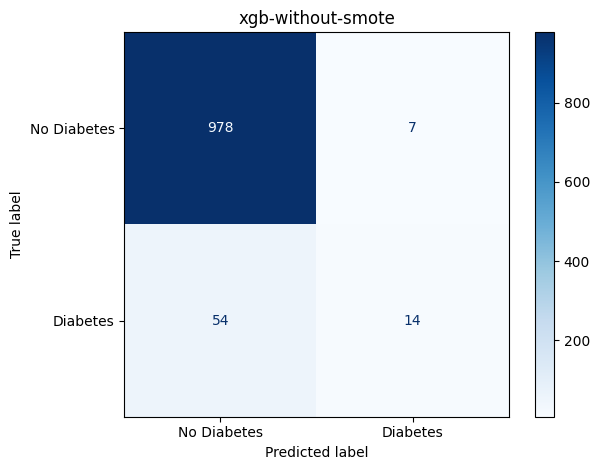

In [87]:
plot_confusion_matrices(models, X_test, y_test)

The model achieved an accuracy of 94.21%; however, this high accuracy is misleading because the model favors the majority class (non-diabetic). It correctly identifies most non-diabetic cases but performs poorly in detecting diabetic cases, resulting in a high number of false negatives (54 out of 68 actual diabetic cases).

This is particularly concerning in a medical context because false negatives mean that individuals with diabetes are incorrectly classified as non-diabetic, potentially delaying further testing, diagnosis, and treatment. Therefore, despite its high overall accuracy, the model's low sensitivity (20.59%) makes it unsuitable for reliable diabetes screening in its current form.